# Summary Assignment for Module 4
<blockquote>This is an assignment in a Jupyter notebook which will be autograded. (It is not a programming assignment but rather is using tools from a Jupyter notebook that allows for calculations and more free-form answers than the other kinds of assignments you have seen so far in this course.) To avoid autograder errors, please do not add or delete any cells. Also, <b>run all cells even if they are hidden</b> and not requiring any input from you. You may add additional calulations or print statements to any cell to help you see the current values of variables you may be working with.
</blockquote>

**Rounding Error:** Ideally, your answers will be given from a direct Python calculation. For example, given a $2 \times 2$ array $A$, if you are asked to multiply the $(1,3)$ entry with the $(2,2)$ entry and to store the result in a variable `x`, you would type

<code>x = A[1,3]*A[2,2]</code>

(Recall that Python uses zero-based indexing so the $(1,3)$ entry is actually coming from the second row.)

However, if you compute `A[1,3]*A[2,2]` and see `0.23719445178`, you could choose to type out the answer as, for example,

<code>x = 0.23719445</code>

<u>as long as you keep at least 3 decimal places of accuracy</u>.

In [1]:
# Run this cell to import the NumPy library with the name "np" and a
# testing library that will be used by the autograder
import numpy as np
import numpy.testing as npt

# Problem 1

Recall our frog/lily pad/fly system from an earlier module:

Four lily pads are floating in a pond. One frog is on one of the lily pads. Each of the other
three lily pads may or may not hold a single fly. (At any given time there are 0 to 3 flies in
this system.)

At each point in time, the frog hops to a new lily pad chosen completely at random from the three lily 
pads the frog is not on. If a fly is on that pad, it is immediately eaten. Furthermore, immediately following the frog’s
move, with probability 1/3, a new fly joins the system, independent of the frog's move. There is at least one open position for
the fly since the frog just moved off of a lily pad. The incoming fly chooses its position at random
from among the open lily pads. Existing flies do not change their locations.

In summary, at each time step the distribution of flies on the lily pad system changes by the
move of the frog, the possible removal of a fly by being eaten, and the possible arrival of a
new fly.

Let $X_{n}$ be the number of flies in the system after the nth series of moves (frog hops, frog possibly eats, new fly possibly joins). $\{X_{}n\}$ is a Markov chain on the state space $S=\{0,1,2,3\}$.

Consider moving from state $1$ to state $0$ in one step. The only way to move down to $0$ flies is for the frog to land on (and therefore eat) the one fly and for no new flies to join the system. The frog will land on the one fly with probability $1/3$ since there are $3$ possible lily pads to hop to and only $1$ with a fly on it. No new fly joins the system with probability $2/3$. Thus, by independence of frog hops and whether or not a new fly joins, we have $P(X_{n+1}=0|X_{n}=1)= (1/3)(2/3) = (2/9)$.

We have already seen that the transition probability matrix is

$$
\begin{array}{lcr} && 0\,\,\,\,\,\,\,\,\,\,1\,\,\,\,\,\,\,\,\,\,2\,\,\,\,\,\,\,\,\,\,3\,\,\,\,\,\\
\bf{P} &=& \begin{array}{c} 0\\1\\2\\3\end{array}\left[ 
\begin{array}{cccc}
2/3 & 1/3 & 0 & 0  \\
2/9 & 5/9 & 2/9 & 0 \\
0 & 4/9 & 4/9 & 1/9 \\
0 & 0 & 2/3 & 1/3\\
\end{array}
\right]
\end{array}
$$

<br><br>
<hr>

<b>Note:</b>The solutions to the parts of this problem will likely rely more heavily on "pen and paper" calculations than other Jupyter notebook assignments as you will have to set up several systems of equations. Ultimately, you will come back to the notebook to solve your systems.

# A Note About Dimensions for Matrix Multiplication

As a reminder, the solution of <br> 

$$
\left[
\begin{array}{cc}
2 & 8\\
-1 & 3
\end{array}
\right] \vec{x} = \left[
\begin{array}{c}
5\\7
\end{array}
\right]
$$

is 
$$
\vec{x} = \left[
\begin{array}{cc}
2 & 8\\
-1 & 3
\end{array}
\right]^{-1} \left[
\begin{array}{c}
5\\7
\end{array}
\right].
$$

This can be computed in Python with the following code.

<pre><code>A = np.zeros((2,2))
A[0,:] = np.array([2,8])
A[1,:] = np.array([-1,3])

B = np.zeros((2,1))
B[0,:] = 5
B[1,:] = 7  
    
x = np.matmul(np.linalg.inv(A),B)</code></pre>

Note that we defined the vector $B$ as a $2 \times 1$ matrix in order to get the dimensions to match for matrix multiplication. The vector $x$ will be $2 \times 1$. If we want the first element of $x$, we need to type <code>x[0,0]</code>. (Typing <code>x[0]</code> will, technically speaking, give you the answer, but in the form of a $1 \times 1$ array, as opposed to a scalar. This can cause unexpected behavior going forward in this lab.) However, the <code>np.matmul</code> command will also work when defining $B$ as a one-dimensional array as follows.

<pre><code>A = np.zeros((2,2))
A[0,:] = np.array([2,8])
A[1,:] = np.array([-1,3])

B = np.zeros((2))
B[0] = 5
B[1] = 7  
    
x = np.matmul(np.linalg.inv(A),B)</code></pre>

Now, we can get the first element of $x$ by simply typing x[0]. 

If you wish, use the next cell to experiment with both pieces of code given here and how you might extract the first or second element of $x$.

In [ ]:
# Free cell for you!


**Part A)** Suppose that the system starts with 2 flies. What is the expected number of steps until the system has 0 flies?

(Be sure to completely finish each transition. If the frog eats the last fly, you still need to ensure that an additional fly has not joined immediately thereafter. In other words, assume that you don't get to observe the intermediate steps in the transitions.)

Save your answer as p1_a.

[ 7.125  9.75  11.25 ]
9.80522


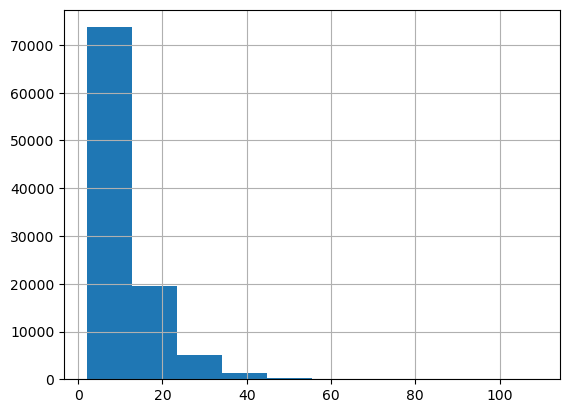

9.75

In [32]:
p1_a = None

# your code here
#raise NotImplementedError
P = np.array([[2/3, 1/3, 0, 0], 
              [2/9, 5/9, 2/9, 0], 
              [0, 4/9, 4/9, 1/9], 
              [0, 0, 2/3, 1/3]])
# ui = E[T | X0 = i]
# u2
# u0 = 0
Q = P[1:,1:]
r = np.ones(3)
w = np.linalg.solve(np.eye(3) - Q, r)
#print(w)
p1_a = w[1]

#eigvals, eigvecs = np.linalg.eig(P.T) # P^T pi = 1.pi <=> pi P = pi.1^T
#v = eigvecs[:, np.isclose(eigvals, 1)].ravel()
## Normalize each eigenvector
#pi = v / v.sum()
#p1_a = 1 / pi[0]

'''
N = 100000
counts = []
for _ in range(N):
    s = 2
    count = 0
    while s != 0:
        s = np.random.choice(4, p=P[s])
        count += 1
    counts.append(count)
print(np.mean(counts))
import matplotlib.pylab as plt
plt.hist(counts)
plt.grid()
plt.show()
'''

p1_a

In [33]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part B)** Suppose that the system starts with 2 flies.  What is the probability that the system becomes full of flies (3 flies) before it becomes empty of flies (0 flies).

(Be sure to completely finish each transition. If the frog eats the last fly, you still need to ensure that an additional fly has not joined immediately thereafter to say that the system is empty. In other words, assume that you don't get to observe the intermediate steps in the transitions.)

Save your answer as p1_b.

In [13]:
p1_b = None

# your code here
#raise NotImplementedError
# p2 # starts at 2 and visits 3
# P = [[2/3, 1/3, 0, 0], 
#      [2/9, 5/9, 2/9, 0], 
#      [0, 4/9, 4/9, 1/9], 
#      [0, 0, 2/3, 1/3]])
# p3 = 1, p0 = 0
# p1 = 2/9*0 + 5/9*p1 + 2/9*p2 + 0*1
# p2 = 0*0 + 4/9*p1 + 4/9*p2 + 1/9*1 
A = np.array([[4/9, -2/9],[-4/9, 5/9]])
b = [0, 1/9]
p1_b = np.linalg.solve(A, b)[1]

'''
N = 100000
count = 0
for _ in range(N):
	s = 2
	while True:
		s = np.random.choice(4, p=P[s])
		if s == 0 or s == 3:
			if s == 3:
				count += 1
			break
print(count / N)
'''
p1_b

0.33333333333333326

In [14]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part C)** Suppose that the system starts with $0$ flies and that we observe the system until the first return to state $0$. What is the probability that we never observe exactly $1$ fly in the system?

Save your answer as p1_c.

Hint: Don't make this too difficult!

(Be sure to completely finish each transition. Assume that you don't get to observe the intermediate steps in the transitions.)

In [16]:
p1_c = None

# your code here
#raise NotImplementedError

'''
N = 100000
count = 0
for _ in range(N):
	s = 0
	while True:
		s = np.random.choice(4, p=P[s])
		if s == 0 or s == 1:
			if s == 0:
				count += 1
			break
print(count / N)
'''
p1_c = 2/3
p1_c

0.6666666666666666

In [17]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part D)** Suppose that the system starts with 0 flies.  What is the expected number of times the system has exactly 1 fly before the first time it returns to 0 flies?

(Be sure to completely finish each transition. If the frog eats the last fly, you still need to ensure that an additional fly has not joined immediately thereafter to say that the system is empty. In other words, assume you don't get to observe the intermediate steps in the transitions.)

Save your answer as p1_d.

In [29]:
p1_d = None

# your code here
#raise NotImplementedError
# w010
# P = [[2/3, 1/3, 0, 0], 
#      [2/9, 5/9, 2/9, 0], 
#      [0, 4/9, 4/9, 1/9], 
#      [0, 0, 2/3, 1/3]])
#w010 = 0
#w110 = 1 + 2/9*0 + 5/9*w110 + 2/9*w210 + 0*w310
#w210 = 0*0 + 4/9*w110 + 4/9*w210 + 1/9*w310
#w310 = 0*0 + 0*w110 + 2/3*w210 + 1/3*w310
A = np.array([[4/9,-2/9,0],[-4/9,5/9,-1/9],[0,-2/3,2/3]])
b = [1,0,0]
w = np.linalg.solve(A, b)
#Q = P[1:, 1:] # states: 1, 2, 3
#r = np.array([1, 0, 0]) # immediate reward: 1 when in state 1
#print(np.eye(3) - Q)
#w = np.linalg.solve(np.eye(3) - Q, r)
#print(w)
p1_d = P[0, 1:] @ w # initial transition from state 0

'''
N = 100000
total = 0
for _ in range(N):
    s = 0
    count = 0
    while True:
        s = np.random.choice(4, p=P[s])
        if s == 1:
            count += 1
        if s == 0:
            break
    total += count
print(total / N)
'''

print(p1_d) 

1.5


In [30]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

# Problem 2

Morse code is a telecommunications method which encodes text characters into sequences or short and long tones known as "dots" and "dashes". 

<img src="morse.png" width="400">

Although Morse code is not meant to be a written language, phrases can be written out with spaces in between letters and a forward slash between words. (For written clarity, we will always include a space on both sides of the forward slash.) For example, we can write MARKOV CHAINS as 

<center>
<h1>
--  .- .-.  -.-  ---  ...- / -.-.  ....  .- ..  -. ...
</h1>
    </center>
   
In total, we have $4$ symbols which we will label $1$ through $4$ as follows.

<ul>
    <li> 1 = dot</li>
    <li> 2 = dash</li>
    <li> 3 = space</li>
    <li> 4 = forward slash</li>
</ul>    

A long corpus of text in the English language was translated into written Morse code. The different observed transitions between symbols were counted and normalized into estimated transition probabilities for the written Morse code for any Engligh language messages. (Note that punctuation is also represented in Morse code by sequences of dots and dashes and was included 


$$
\begin{array}{lcr} && 1\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,2\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,3\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,\,4\,\,\,\,\,\,\,\,\,\\
\bf{P} &=& \begin{array}{c} 1\\2\\3\\4\end{array}\left[ 
\begin{array}{cccc}
0.3561&0.3372&0.2578&0.0489\\
0.4129&0.3366&0.2204&0.0301\\
0.5185&0.3282&0&0.1533\\
0&0&1&0
\end{array}
\right]
\end{array}
$$


**Part A)** Given that the first letter of a word starts with a dot, what is the expected number of Morse characters (dots, dashes, and spaces) for a random word before you encounter the forward slash that ends the word. Include the final space before the slash. Do not include the starting dot and do not include the ending  slash. 

(Hint: Find the expected hitting time on the slash and subtract $1$ to remove the slash character from your expected word length.)

Save your answer as p2_a.

In [24]:
p2_a = None

# your code here
#sraise NotImplementedError
P = np.array([[0.3561,0.3372,0.2578,0.0489],
             [0.4129,0.3366,0.2204,0.0301],
             [0.5185,0.3282,0,0.1533],
             [0,0,1,0]])
# u4 = 0 # ui = E[T|X0=i]
# u1 = 1 + 0.3561*u1 + 0.3372*u2 + 0.2578*u3
# u2 = 1 + 0.4129*u1 + 0.3366*u2 + 0.2204*u3
# u3 = 1 + 0.5185*u1 + 0.3282*u2 + 0*u3
#A = np.array([[1-0.3561,-0.3372,-0.2578],[-0.4129,1-0.3366,-0.2204],[-0.5185,-0.3282,1]])
#b = [1,1,1]
#w = np.linalg.solve(A, b)
#print(w)

Q = P[:3, :3] # states: 1, 2, 3
r = np.ones(3) 
w = np.linalg.solve(np.eye(3) - Q, r)
#print(w)

p2_a = w[0] - 1

'''
N = 100000
lengths = []
for _ in range(N):
    s = 0
    length = 0
    while True:
        s = np.random.choice(4, p=P[s])
        if s == 3:
            break
        length += 1
    lengths.append(length
                  )
print(np.mean(lengths))
import matplotlib.pylab as plt
plt.hist(lengths)
plt.grid()
plt.show()
'''

p2_a

14.884448356207484

In [8]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part B)** Given that the first letter of a word starts with a dot, follow the characters forward until the word ends with a slash. What is the expected number of spaces along the way? (Include the final space before the slash.)

Save your answer as p2_b.

In [25]:
p2_b = None

# your code here
#raise NotImplementedError
# w023
# P = np.array([[0.3561,0.3372,0.2578,0.0489],
#               [0.4129,0.3366,0.2204,0.0301],
#               [0.5185,0.3282,0,     0.1533],
#               [0,     0,     1,     0]])
#w023 = 0.3561*w023 + 0.3372*w123 + 0.2578*w223
#w123 = 0.4129*w023 + 0.3366*w123 + 0.2204*w223
#w223 = 1 + 0.5185*w023 + 0.3282*w123 + 0*w223
#A = np.array([[1-0.3561,-0.3372,-0.2578],[-0.4129,1-0.3366,-0.2204],[-0.5185,-0.3282,1]])
#b = [0,0,1]
#w = np.linalg.solve(A, b)
#print(w)

Q = P[:3, :3] # states: 1, 2, 3
r = np.array([0, 0, 1]) # immediate reward: 1 when in state 1
w = np.linalg.solve(np.eye(3) - Q, r)
#print(w)

p2_b = w[0] # initial transition from state 0

'''
N = 100000
total = 0
for _ in range(N):
    s = 0
    count = 0
    while s != 3:
        s = np.random.choice(4, p=P[s])
        if s == 2:
            count += 1
    total += count
print(total / N)
'''

print(p2_b)

3.0973522227850636


In [15]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part C)** What is the expected number of total dots and dashes in a word randomly selected from the corpus and translated into Morse code given that the first letter of the word starts with a dot? (Include the starting dot.)

Save your answer as p2_c.

(Hint: Don't make this too difficult. You have already done most of the work!)

In [27]:
p2_c = None

# your code here
#raise NotImplementedError
p2_c = p2_a - p2_b + 1 #Include the starting dot.

'''
N = 100000
total = 0
for _ in range(N):
    s = 0
    count = 0
    while s != 3:
        if s == 0 or s == 1:
            count += 1
        s = np.random.choice(4, p=P[s])
    total += count
print(total / N)
'''

print(p2_c)

12.78709613342242


In [ ]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part D)** What is the expected number of total Latin alphabet letters (English letters) in a word randomly selected from the corpus and translated into Morse code given that the first letter of the word starts with a dot?

Save your answer as p2_d.

In [19]:
p2_d = None

# your code here
#raise NotImplementedError
p2_d = p2_b
p2_d

2.0973522227850636

In [20]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.

**Part E)** Find, if it exists, a stationary distribution for this chain.

Save your answer as a vector <code>p2_e</code> of length $4$, with entries representing $\pi_{1}$ through $\pi_{4}$, respectively. If the chain does not have a stationary distribution, assign p2_e to be a vector of zeros.

In [36]:
p2_e = None

# your code here
#raise NotImplementedError
P = np.array([[0.3561,0.3372,0.2578,0.0489], 
             [0.4129,0.3366,0.2204,0.0301], 
             [0.5185,0.3282,0,0.1533], 
             [0,0,1,0]])
#P

#Ps = P.copy()
#for _ in range(1000):
#    Ps = Ps@P
#print(Ps)

eigvals, eigvecs = np.linalg.eig(P.T) # P^T pi = 1.pi <=> pi P = pi.1^T
v = eigvecs[:, np.isclose(eigvals, 1)]
pi = v / v.sum(axis=0)
p2_e = pi.ravel()
p2_e

array([0.38894214, 0.31324395, 0.23356108, 0.06425283])

In [37]:
# Hidden Test Cell
# NOTE: This cell contains hidden tests. You will not see whether you passed these tests until you submit your assignment.
# Any cell labeled "Hidden Test Cell" MAY have hidden tests.